In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from blo_optimisers import *
from typing import Dict
import copy
import pickle
import matplotlib
from functools import partial
import timeit

class LinearModel(nn.Module):
    """Simple neural network for demonstration"""
    def __init__(self, input_dim=10, output_dim=1, initial_weights:torch.Tensor=None, seed:int=None):
        super().__init__()
        if seed is not None:
            torch.manual_seed(seed)
        self.fc1 = nn.Linear(input_dim, output_dim,bias=False)
        with torch.no_grad():
            if initial_weights is not None:
                self.fc1.weight.copy_(initial_weights)
    
    def forward(self, x):
        return self.fc1(x)

class ScalarModule(nn.Module):
    def __init__(self, value=1.0):
        super().__init__()
        self.value = nn.Parameter(torch.tensor(float(value)))
    def forward(self):
        return self.value


def run_single(method, hparams:dict, w0, th0,
               num_iters,data,batch_size:int=1, seed:int=0):
    
    optimiser = build_optimiser(method, w0, th0,hparams)

    ll_loss = []
    ul_loss = []
    excess_ll_loss = []
    excess_ul_loss = []

    # full-data arrays for evaluating excess losses at each iterate
    Xt, yt = data['X_train'].double().numpy(), data['y_train'].double().numpy()
    Xv, yv = data['X_val'].double().numpy(),   data['y_val'].double().numpy()
    lam_min_Ht = np.linalg.eigvalsh(Xt.T@Xt/len(yt)).min()

    _,_, ul_min, _ = BilevelRidgeProblemOptimalSolution(data, verbose=False)
    ul_min = float(ul_min)

    for iter in range(num_iters):
        data_point = data_batch(data, batch_size=batch_size,seed=seed+iter)
        res = optimiser.step(data_point)
        ll_loss.append(res['ll_loss'])
        ul_loss.append(res['ul_loss'])

        # current iterate (w0/th0 are updated in place by every optimiser)
        w = w0.fc1.weight.detach().double().numpy().T
        th = th0.value.item()
        J = np.mean((Xt@w - yt)**2) + th*(w.T@w).item()
        F_ = np.mean((Xv@w - yv)**2)

        # LL has no minimum when Ht + th*I is not positive definite
        if th > -lam_min_Ht:
            _, ll_min = SingleLevelRidgeProblemOptimalSolution(data, th)
            excess_ll_loss.append(J - float(ll_min))
        else:
            excess_ll_loss.append(np.nan)
        excess_ul_loss.append(F_ - ul_min)
    return {'ll_loss': ll_loss, 'ul_loss': ul_loss, 'excess_ul_loss':excess_ul_loss, 'excess_ll_loss': excess_ll_loss}


def run_sweep(method,hparams:dict,num_iters,data,
              th0_low, th0_high, th0_N,
              w0_N, batch_size:int=1, seed:int=0,verbose=True): 

    if verbose:
        print(f'{method}: {th0_N*w0_N} runs')
    results = {'history_ll_loss': [],'history_ul_loss': [],'history_excess_ll_loss': [],'history_excess_ul_loss': []}
    for th_val in np.linspace(th0_low, th0_high, th0_N):
        for w0_seed in range(w0_N):

            th0 = ScalarModule(th_val)
            w0 = LinearModel(input_dim=M,seed=seed+w0_seed)
            res = run_single(method, hparams,w0, th0, num_iters=num_iters,data=data, batch_size=batch_size )
            results['history_ll_loss'].append(res['ll_loss'])
            results['history_ul_loss'].append(res['ul_loss'])
            results['history_excess_ll_loss'].append(res['excess_ll_loss'])
            results['history_excess_ul_loss'].append(res['excess_ul_loss'])

    ul = np.array(results['history_ul_loss'])                        
    ll = np.array(results['history_ll_loss'])                        
    excess_ul = np.array(results['history_excess_ul_loss'])
    excess_ll = np.array(results['history_excess_ll_loss'])
    valid = np.all(np.isfinite(ul), axis=1)
    if verbose:
        print(f'{(~valid).sum()} / {len(valid)} runs diverged and excluded') 
    results['n_diverged'] = int((~valid).sum())    
    results['median_ul_loss'] = np.median(np.abs(ul[valid]),0)
    results['median_ll_loss'] = np.median(np.abs(ll[valid]),0)
    results['mean_ll_loss'] = np.mean(np.abs(ll[valid]),0)
    results['mean_ul_loss'] = np.mean(np.abs(ul[valid]),0)
    # nan-aware: excess LL is nan while theta <= -lambda_min(Ht)
    results['median_excess_ul_loss'] = np.nanmedian(np.abs(excess_ul[valid]),0)
    results['median_excess_ll_loss'] = np.nanmedian(np.abs(excess_ll[valid]),0)
    results['mean_excess_ll_loss'] = np.nanmean(np.abs(excess_ll[valid]),0)
    results['mean_excess_ul_loss'] = np.nanmean(np.abs(excess_ul[valid]),0)
    return results


def ScoreCurve(results, window:int=100)->float:
    ll = np.asarray(results['mean_excess_ll_loss'])
    ul = np.asarray(results['mean_excess_ul_loss'])
    auc = np.mean(np.log10(ll.clip(1e-16))) + np.mean(np.log10(ul.clip(1e-16)))
    mask = (ll < ITER_COMP_TOL) & (ul < ITER_COMP_TOL)
    iter_comp = int(np.argmax(mask)) if mask.any() else None
    return iter_comp, auc


def RidgeProblemConditionNumber(H, w0):
    z = np.zeros_like(w0)
    KKT_mat = np.block([[H,z,H],[z.T, 0, w0.T],[H,w0, z@z.T]])
    return np.linalg.cond(KKT_mat)

def SingleLevelRidgeProblemOptimalSolution(data,theta0:float, verbose:bool=False):

    _, M = data['X_train'].shape
    Nt = len(data['y_train'])
    Ht =( 1/Nt*data['X_train'].T@data['X_train']).detach().numpy()
    rt = ( 1/Nt*data['X_train'].T@data['y_train']).detach().numpy()

    w0 = np.linalg.inv(Ht+theta0*np.eye(M,M))@rt

    Xt, yt = data['X_train'].numpy(), data['y_train'].numpy()
    ll_min = np.mean((Xt@w0 - yt)**2) + theta0*(w0.T@w0).item()

    return w0, ll_min

def BilevelRidgeProblemOptimalSolution(data, verbose:bool=False):

    Nt, Nv = [len(data['y_train']), len(data['y_val'])]
    _, M = data['X_train'].shape


    Ht =( 1/Nt*data['X_train'].T@data['X_train']).detach().numpy()
    Hv =(1/Nv*data['X_val'].T@data['X_val']).detach().numpy()
    rt = ( 1/Nt*data['X_train'].T@data['y_train']).detach().numpy()
    rv =  (1/Nv*data['X_val'].T@data['y_val']).detach().numpy()

    # print(Ht.type(), rt.type())
    th0 = sum(rt-Ht@np.linalg.inv(Hv)@rv)/sum(np.linalg.inv(Hv)@rv)
    w0 = np.linalg.inv(Hv)@rv

    Xt, yt = data['X_train'].numpy(), data['y_train'].numpy()
    Xv, yv = data['X_val'].numpy(), data['y_val'].numpy()
    ll_min = np.mean((Xt@w0 - yt)**2) + th0.item()*(w0.T@w0).item()
    ul_min = np.mean((Xv@w0 - yv)**2)

    assert (w0>0).all() # solution set based on assumption w*>0 

    feasibility_constraint = sum(np.abs((Ht+th0*np.eye(M,M))@w0-rt))

    if verbose:
        print(f'Solved parameters:\n\ttheta*:{th0}\n\tw*: {w0.T}')
        print(f'\t constraint error: {feasibility_constraint[0]}')

    return w0, th0, ul_min, ll_min

def BilevelRidgeProblemConditionNumberTrue(data, verbose:bool=False):

    Nt, Nv = [len(data['y_train']), len(data['y_val'])]
    _, M = data['X_train'].shape


    Ht =( 1/Nt*data['X_train'].T@data['X_train']).detach().numpy()
    Hv =(1/Nv*data['X_val'].T@data['X_val']).detach().numpy()

    w0, th0,_,_ = BilevelRidgeProblemOptimalSolution(data, verbose)

    assert (w0>0).all() # solution set based on assumption w*>0 

    
    z = np.zeros_like(w0)
    KKT_mat = np.block([[Hv,z,Ht+th0*np.eye(M,M)],[z.T, 0, w0.T],[Ht+th0*np.eye(M,M),w0, z@z.T]])
    cond_no = np.linalg.cond(KKT_mat)
    if verbose:
        print(f'\t KKT condition no.: {cond_no}')

    return cond_no

# def tune_single(method,hparams:dict, param_name, param_range, num_iters,data,
#         th0_low, th0_high, th0_N,
#         w0_N, batch_size:int=1, seed:int=0,verbose=True):

#     best_hparam = None
#     best_score = np.inf
#     best_iter_comp = None
#     best_auc = np.inf
#     print(f'Tuning {param_name}')
#     for param_val in param_range:
#         hparams[method][param_name] = param_val
#         res = run_sweep(method, hparams, num_iters=num_iters,data=data, 
#                         batch_size=batch_size, w0_N=w0_N, 
#                         th0_N=th0_N, th0_high=th0_high, th0_low=th0_low, seed=seed,verbose=False)
#         iter_comp, auc = ScoreCurve(res)
#         if iter_comp is not None:
#               if best_iter_comp is None or iter_comp < best_iter_comp:
#                   best_iter_comp = iter_comp
#                   best_hparam = param_val
#               score_str = f'iter_comp={iter_comp}'
#         else:
#             if best_iter_comp is None and auc < best_auc:
#                 best_auc = auc
#                 best_hparam = param_val
#             score_str = f'auc={auc:.3f}'

#         if verbose:
#             print(f'\t {param_name}={param_val} {score_str} best=({best_hparam})')

#     best_score = best_iter_comp if best_iter_comp is not None else best_auc
#     print(f'\tbest=({best_hparam}) score:{best_score}')

#     return best_hparam, best_score
def IterComplexity(J, F, tol):
    J_iter = np.argmax(J<tol)
    F_iter = np.argmax(F<tol)
    if (not J_iter) or (not F_iter):
        return np.nan
    return np.max([J_iter, F_iter])

def tune_single(method, hparams, param_name, param_range,force_converge:bool=False, **run_kwargs):
    best_hparam, best_iter_comp, best_auc_at_best_ic, best_auc = None, None, np.inf, np.inf
    print(f'  tuning {param_name} ...', flush=True)
    for val in param_range:
        hparams[method][param_name] = val
        try:
            res = run_sweep(method, hparams, **run_kwargs)
            ic, auc = ScoreCurve(res)
            if force_converge and res['n_diverged']>0:
                print(f'    {param_name}={val:.5g}  n_diverged: {res["n_diverged"]}', flush=True)
                continue
        except Exception as e:
            print(f'    {param_name}={val:.5g}  ERROR: {e}', flush=True)
            continue
        if ic is not None:
            # tie-break on auc when iter_comp is equal
            if best_iter_comp is None or ic < best_iter_comp or (ic == best_iter_comp and auc < best_auc_at_best_ic):
                best_iter_comp, best_auc_at_best_ic, best_hparam = ic, auc, val
            score_str = f'iter_comp={ic}  auc={auc:.3f}'
        else:
            if best_iter_comp is None and auc < best_auc:
                best_auc, best_hparam = auc, val
            score_str = f'auc={auc:.3f}' if auc is not None else  f'auc=NONE'
        print(f'    {param_name}={val:.5g}  {score_str}  best={best_hparam}', flush=True)
    best_score = best_iter_comp if best_iter_comp is not None else best_auc
    print(f'    → {param_name} = {best_hparam}  (score={best_score})', flush=True)
    return best_hparam


device=torch.device("cpu")   
SGD_MOMENTUM = partial(torch.optim.SGD, momentum=0.9)

def build_optimiser(method, w0, th0, hparams):
    h = hparams[method]
    common = dict(ll_model=w0, ul_model=th0, lower_loss_fn=lower_loss, upper_loss_fn=upper_loss,
                  stochastic=False, device=device)

    if method == "PABLO":
        rms = {"alpha": h["alpha"]}
        return BLO_optimiser_PABLO_Prox_Bound(**common,
            w_optimiser=torch.optim.RMSprop, theta_optimiser=torch.optim.RMSprop, lambda_optimiser=torch.optim.SGD,
            w_optimiser_kwargs=rms, theta_optimiser_kwargs=rms,
            lr_w=h["lr_w"], lr_theta=h["lr_theta"], rho=h["rho"], lr_lambda=h["lr_lambda"],
            tau=h["tau"], gamma=h["y_rate"] / h["tau"], lambda_bound=h["lambda_bound"], grad_clip=h["grad_clip"],
            warmup_ratio=h.get("warmup_ratio", None), total_steps=h.get("total_steps",None))

    if method == "BOME":
        bome_opt = {"sgdm": SGD_MOMENTUM, "adam": torch.optim.Adam, "rmsprop": torch.optim.RMSprop}[h.get("opt", "sgdm")]
        return BLO_optimiser_BOME(**common, inner_steps=h["inner_steps"], inner_lr=h["inner_lr"], eta=h["eta"],
            lr_w=h["lr_w"], lr_theta=h["lr_theta"], w_optimiser=bome_opt, theta_optimiser=bome_opt,
            barrier=h["barrier"])

    if method == "TSP":
        return BLO_optimiser_TSP(**common, **h)

    if method == "STABLE":
            return BLO_optimiser_STABLE(**common, **h)

    if method == "AID":
        return BLO_optimiser_AID_Neumann(**common, **h)

    if method == "AAL":
        return BLO_optimiser_AAL(**common, **h)

    if method == "PBGD-Free":
        return BLO_optimiser_PBGD_Free(**common, **h)

    raise ValueError(f"unknown method: {method}")



COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AID": "#3b7dd8", "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}




### Data Generation

In [5]:

def data_batch(data, batch_size, seed) -> dict[str, torch.Tensor]:
    rng_train = torch.Generator().manual_seed(seed)
    idx_t = torch.randperm(data['X_train'].shape[0], generator=rng_train)[:batch_size]
    rng_val = torch.Generator().manual_seed(seed)
    idx_v = torch.randperm(data['X_val'].shape[0], generator=rng_val)[:batch_size]
    return {'X_train': data['X_train'][idx_t],
            'y_train': data['y_train'][idx_t],
            'X_val': data['X_val'][idx_v],
            'y_val': data['y_val'][idx_v],}


def make_data(feature_cov:np.ndarray, 
              feature_dim:int, 
                noise_var:float, 
                w_true:np.ndarray,
                N_val:int, N_train:int,seed:int) -> dict[str, torch.Tensor]:

    if w_true is None:
        w_true = np.ones([feature_dim,1])
    w_true = np.asarray(w_true, dtype=np.float64)

    rng = np.random.default_rng(seed)

    X_train = rng.multivariate_normal(np.zeros(feature_dim), feature_cov, size=N_train)
    y_train = X_train@w_true + noise_var*rng.random((N_train,1))

    X_val= rng.multivariate_normal(np.zeros(feature_dim), feature_cov, size=N_val)
    y_val = X_val@w_true + noise_var*rng.random((N_val,1))
   
    return {
        'X_train': torch.tensor(X_train, dtype=torch.float32),
        'y_train': torch.tensor(y_train, dtype=torch.float32),
        'X_val':   torch.tensor(X_val, dtype=torch.float32),
        'y_val':   torch.tensor(y_val, dtype=torch.float32),
    }

SEED=0
M = 10
NOISE_VAR=0.1
W_TRUE = np.ones([M,1])
N_VAL, N_TRAIN = [1000, 1000]
H = np.eye(M,M)

data = make_data(feature_cov=H,feature_dim=M,noise_var=NOISE_VAR,N_train=N_TRAIN, N_val=N_VAL,
                 w_true=W_TRUE,seed=SEED)

In [6]:
LL_REG = 0.0

def lower_loss(ll_model, data, ul_model, stochastic=False, seed=None, **kwargs):
    """J(w, theta): sample-weighted training cross-entropy"""

    features, labels = data["X_train"], data["y_train"]

    loss = F.mse_loss(ll_model(features), labels, reduction="mean")
    w_norm = sum((p.square()).sum() for p in ll_model.parameters())

    return loss + ul_model()*w_norm



def upper_loss(ll_model, data, ul_model, stochastic=False, seed=None, **kwargs):
    """F(w, theta): validation cross-entropy"""

    features, labels = data["X_val"], data["y_val"]

    loss = F.mse_loss(ll_model(features), labels, reduction="mean")
    return loss

Good for H[0,0]=1
HPARAMS = {
        'PABLO': {'lr_w': 0.07039, 'lr_theta': 0.01880, 'alpha': 0.999, 'eps': 1e-6, 
                  'rho': 0.01887, 'lr_lambda': 0.01887, 'tau':0.32903, 'y_rate': 0.594, 'grad_clip': 10, 
                  'lambda_bound': 0.1269, 'total_steps': None},          
        "BOME":  dict(opt="sgdm", inner_steps=10, inner_lr=0.0788, eta=1.3738, lr_w=0.01887, lr_theta=0.007279, barrier="grad_norm"),
        # "TSP": dict(alpha=0.05, eta=0.0001,tau=0.0001,gamma=0.1, delta=0.0, p=0.0001, mu=.05, 
        #             theta=0.05, omega=0.891, lambda_init=0.0788, beta=0.05),
        "TSP": dict(alpha=0.5, eta=0.05,tau=0.0001,gamma=0.07, delta=0.0, p=0.1, mu=.05, 
                    theta=0.05, omega=0.4, lambda_init=0.08, beta=0.05),
        "AAL": dict(rho0=0.01, alpha=0.005, eps=0.085, t=50, tau=0.01),
        "STABLE":   dict(lr_w=0.5, lr_theta=0.1, tau=0.1, mu_g=0.5, C_gxy=1),
        "PBGD-Free": dict(gamma=10.0, eta=0.5, eta_gamma=0.01, K=1), }



In [4]:



    # "TSP": dict(gamma=0.25, delta=0.0, p=0.003, eta_z=0.003, lr_y=0.033, lr_x=225, dual_lr=0.7,
    #             constraint_ema=0.01, lambda_ema=1.0, anchor_ema=0.5, lambda_init=5.0),
    #       gamma  Moreau smoothing parameter        delta  constraint slack
    #   p      proximal (anchor) weight          tau    dual step size
    #   mu     dual smoothing (lambda EMA)       theta  constraint smoothing (h EMA)
    #   eta    z step size                       alpha  x step size
    #   beta   y step size                       omega  anchor EMA
    # "TSP": dict(gamma=1.1, delta=0.0, p=1, eta=0.5, beta=0.5, alpha=0.5, tau=0.005,
    #         theta=0.5, mu=0.05, omega=0.1, lambda_init=0.77),

#TUNED for H[0,0]=1
# HPARAMS = {
#         'PABLO': {'lr_w': 0.07039, 'lr_theta': 0.01880, 'alpha': 0.999, 'eps': 1e-6, 
#                   'rho': 0.01887, 'lr_lambda': 0.01887, 'tau':0.32903, 'y_rate': 0.594, 'grad_clip': 10, 
#                   'lambda_bound': 0.1269, 'total_steps': None},          
#         "BOME":  dict(opt="sgdm", inner_steps=10, inner_lr=0.0788, eta=1.3738, lr_w=0.01887, lr_theta=0.007279, barrier="grad_norm"),
#         # "TSP": dict(alpha=0.05, eta=0.0001,tau=0.0001,gamma=0.1, delta=0.0, p=0.0001, mu=.05, 
#         #             theta=0.05, omega=0.891, lambda_init=0.0788, beta=0.05),
#         "TSP": dict(alpha=0.5, eta=0.05,tau=0.0001,gamma=0.07, delta=0.0, p=0.1, mu=.05, 
#                     theta=0.05, omega=0.4, lambda_init=0.08, beta=0.05),
#         "AAL": dict(rho0=0.01, alpha=0.003, eps=1e-6, t=30, tau=0.2),
#         "STABLE":   dict(lr_w=0.5, lr_theta=0.1, tau=0.1, mu_g=0.5, C_gxy=1),
#         "PBGD-Free": dict(gamma=10.0, eta=0.5, eta_gamma=0.01, K=1), }
HPARAMS = {
      'PABLO': {
          'lr_w': 0.02112,        # 0.07039 × 0.3
          'lr_theta': 0.01564,    # 0.01880 × 0.3
          'lr_lambda': 0.00566,   # 0.01887 × 0.3
          'rho': 0.01887,         # unchanged
          'alpha': 0.999,
          'eps': 1e-6,
          'tau': 0.32903,
          'y_rate': 0.594,
          'grad_clip': 10,
          'lambda_bound': 0.1269,
          'total_steps': None,
      },
      'BOME': {
          'opt': "sgdm",
          'inner_steps': 10,
          'inner_lr': 0.03940,    # 0.0788 × 0.5
          'eta': 0.6869,          # 1.3738 × 0.5
          'lr_w': 0.00944,        # 0.01887 × 0.5
          'lr_theta': 0.003640,   # 0.007279 × 0.5
          'barrier': "grad_norm",
      },
      'TSP': {'alpha': 0.5, 'beta': 0.05, 'eta': 0.05, 'gamma': 0.07, 'delta': 0.0, 
              'p': 0.1, 'tau': 0.0001, 'mu': 0.05, 'theta':0.05, 'omega': 0.4, 'lambda_init': 0.08,},
        'AAL': { 'rho0': 0.75, 'alpha': 2e-3, 'eps': 1e-6, 't': 500, 'tau': 0.01, },
  }

# Tuning p
# /Users/aaronfainman/.pyenv/versions/3.12.12/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
#   return _methods._mean(a, axis=axis, dtype=dtype,
# /Users/aaronfainman/.pyenv/versions/3.12.12/lib/python3.12/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
#   ret = um.true_divide(
# 	best=(0.8858667904100823)
# Tuning gamma
# 	best=(0.012742749857031334)
# Tuning alpha
# 	best=(5.455594781168514)
# Tuning eta
# 	best=(0.0011288378916846883)
# Tuning tau
# 	best=(0.0001)

# METHODS = [ "PABLO"]#, "PBGD-Free"]
METHODS = ["PABLO", "BOME", "TSP", "AAL"]#, "PBGD-Free"]



In [5]:
SEED=0
M = 10
NOISE_VAR=0.1
W_TRUE = np.ones([M,1])
N_VAL, N_TRAIN = [1000, 1000]
H = np.eye(M,M)
H[0,0] = 10

data = make_data(feature_cov=H,feature_dim=M,noise_var=NOISE_VAR,N_train=N_TRAIN, N_val=N_VAL,
                 w_true=W_TRUE,seed=SEED)

In [6]:



LOW = -2
HIGH = 2
N_GRID = 3
N_ITERS = 1000
BATCH_SIZE = 10
w0_N = 2
th0_HIGH = 2
th0_LOW = -2

RUN_KWARGS = dict(num_iters=N_ITERS,data=data, batch_size=BATCH_SIZE,
                w0_N=N_GRID, th0_N=N_GRID, th0_high=th0_HIGH,th0_low=th0_LOW, seed=SEED)

sweep_res = {}
for m in METHODS:
    sweep_res[m] = run_sweep(m,HPARAMS, **RUN_KWARGS)



PABLO: 9 runs
0 / 9 runs diverged and excluded
BOME: 9 runs
0 / 9 runs diverged and excluded
TSP: 9 runs
0 / 9 runs diverged and excluded
AAL: 9 runs
9 / 9 runs diverged and excluded


/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/site-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


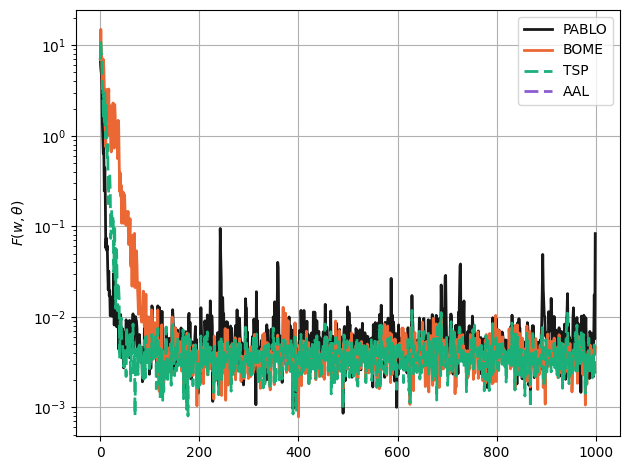

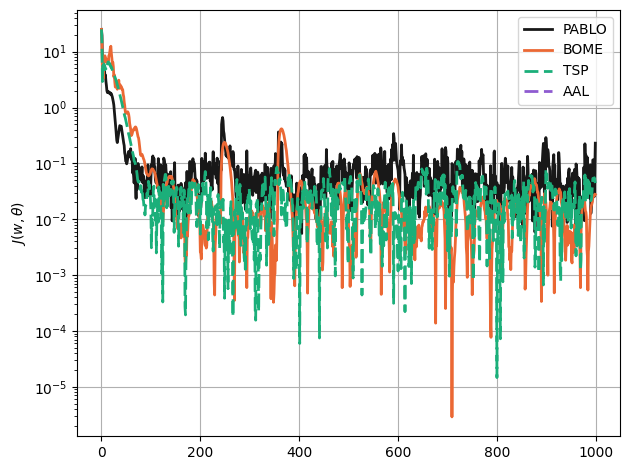

In [7]:

for m in sweep_res.keys():
    plt.semilogy(sweep_res[m]['mean_ul_loss'], label=m, color=COLOURS[m], 
                 linestyle=LINESTYLES[m], linewidth=2)
plt.legend()
plt.grid(True)
plt.ylabel(r'$F(w,\theta)$')
plt.tight_layout()
plt.show()

for m in sweep_res.keys():
    plt.semilogy(sweep_res[m]['mean_ll_loss'], label=m, color=COLOURS[m],
                 linestyle=LINESTYLES[m], linewidth=2)
plt.legend()
plt.grid(True)
plt.ylabel(r'$J(w,\theta)$')
plt.tight_layout()
plt.show()


# plt.semilogy(res['mean_ll_loss'])
# plt.semilogy(res['mean_ul_loss'])
# plt.semilogy(res['ul_loss'])

# SWEEP

In [ ]:
# data parameters
SEED=0
M = 10
NOISE_VAR=0.1
W_TRUE = np.ones([M,1])
N_VAL, N_TRAIN = [1000, 1000]


# sweep parameters
LOW = -2
HIGH = 2
N_GRID = 3
N_ITERS = 300
BATCH_SIZE = 10
w0_N = 2
th0_HIGH = 2
th0_LOW = -2
NUM_SEEDS = 10


HPARAMS = {
    1: {
        'PABLO': {'lr_w': 0.0141, 'lr_theta': 0.0132, 'alpha': 0.999, 'eps': 1e-6, 
                                          'rho': 0.25, 'lr_lambda': 0.0328, 'tau':0.32903, 'y_rate': 0.594, 'grad_clip': 10, 
                                          'lambda_bound': 0.01, 'total_steps': None},          
        "BOME": {'opt': "sgdm",'inner_steps': 10,'inner_lr': 0.03940, 'eta': 0.6869,'lr_w': 0.0249, 'lr_theta': 0.01457, 'barrier': "grad_norm"},
        "TSP": dict(alpha=2.4, eta=0.05,tau=0.0001,gamma=0.07, delta=0.0, p=0.001, mu=.05, 
                                            theta=0.05, omega=0.4, lambda_init=0.08, beta=0.075),
        'AAL': { 'rho0': 0.03, 'alpha': 0, 'eps': 1e-6, 't': 4.4, 'tau': 0.03, },
        "STABLE":   dict(lr_w=0.125, lr_theta=0.047, tau=0.45, mu_g=1.5, C_gxy=1000),
        "PBGD-Free": dict(gamma=10.0, eta=0.5, eta_gamma=0.01, K=1),
    },
    5: {
        'PABLO': {'lr_w': 0.015, 'lr_theta': 0.0120, 'alpha': 0.999, 'eps': 1e-6, 
                                  'rho': 0.27, 'lr_lambda': 0.03, 'tau':0.32903, 'y_rate': 0.594, 'grad_clip': 10, 
                                  'lambda_bound': 0.001, 'total_steps': None},          
        "BOME": {'opt': "sgdm",'inner_steps': 10,'inner_lr': 0.03940, 'eta': 0.6869,'lr_w': 0.01777, 'lr_theta': 0.01457, 'barrier': "grad_norm"},
        "TSP": dict(alpha=2.4, eta=0.05,tau=0.0001,gamma=0.07, delta=0.0, p=0.001, mu=.05, 
                            theta=0.05, omega=0.4, lambda_init=0.08, beta=0.065),
        'AAL': { 'rho0': 0.03, 'alpha': 0, 'eps': 1e-6, 't': 11, 'tau': 0.03, },
        "STABLE":   dict(lr_w=0.075, lr_theta=0.027, tau=0.45, mu_g=1.6, C_gxy=1000),
        "PBGD-Free": dict(gamma=10.0, eta=0.5, eta_gamma=0.01, K=1),
    },
    10: {
        'PABLO': {'lr_w': 0.01, 'lr_theta': 0.02, 'alpha': 0.999, 'eps': 1e-6, 
                                          'rho': 0.1, 'lr_lambda': 0.03, 'tau':0.1, 'y_rate': 0.5, 'grad_clip': 10, 
                                          'lambda_bound': 0.003,},
        "STABLE":   dict(lr_w=0.06, lr_theta=0.02, tau=0.58, mu_g=1.6, C_gxy=1000),
        "BOME": {'opt': "sgdm",'inner_steps': 10,'inner_lr': 0.03940, 'eta': 0.6869,'lr_w': 0.0037, 'lr_theta': 0.003640, 'barrier': "grad_norm"},
        "TSP": dict(alpha=0.91, eta=0.05,tau=0.0001,gamma=0.07, delta=0.0, p=0.001, mu=.05, 
                                    theta=0.05, omega=0.4, lambda_init=0.08, beta=0.065),
        'AAL': { 'rho0': 0.03, 'alpha': 0, 'eps': 1e-6, 't': 27, 'tau': 0.03, }
    },
    20: {
        'PABLO': {'lr_w': 0.0085, 'lr_theta': 0.015, 'alpha': 0.999, 'eps': 1e-6, 
                                        'rho': 0.02, 'lr_lambda': 0.0106, 'tau':0.3, 'y_rate': 0.1, 'grad_clip': 10, 
                                        'lambda_bound': 0.013, 'total_steps': None},
        "BOME": {'opt': "sgdm",'inner_steps': 10,'inner_lr': 0.02, 
                 'eta': 0.05,'lr_w': 0.0025, 'lr_theta': 0.02, 'barrier': "grad_norm"},
        "STABLE":   dict(lr_w=0.03, lr_theta=0.03, tau=0.45, mu_g=3, C_gxy=1000),
        "TSP": dict(alpha=1.1, eta=0.02,tau=0.0001,gamma=0.074, delta=0.0, p=0.0001, mu=.05, 
                                            theta=0.05, omega=0.4, lambda_init=0.08, beta=0.02),
        'AAL': { 'rho0': 0.03, 'alpha': 1e-5, 'eps': 1e-6, 't': 100, 'tau': 0.03, }
    },
    30: {
        'PABLO': {'lr_w': 0.008, 'lr_theta': 0.0171, 'alpha': 0.999, 'eps': 1e-6, 
                                'rho': 0.02, 'lr_lambda': 0.0106, 'tau':0.3, 'y_rate': 0.1, 'grad_clip': 10, 
                                'lambda_bound': 0.013, 'total_steps': None},
        "BOME": {'opt': "sgdm",'inner_steps': 10,'inner_lr': 0.015, 
                         'eta': 0.00114,'lr_w': 0.0027, 'lr_theta': 0.0375, 'barrier': "grad_norm"},
        "STABLE": dict(lr_w=0.022, lr_theta=0.04, tau=0.45, mu_g=3, C_gxy=1000),
        "TSP": dict(alpha=1.9, eta=0.014,tau=0.0001,gamma=0.074, delta=0.0, p=0.0001, mu=.05, 
                                                            theta=0.05, omega=0.4, lambda_init=0.08, beta=0.02),
        'AAL': { 'rho0': 0.03, 'alpha': 1e-9, 'eps': 1e-6, 't': 231, 'tau': 0.03, }
    },
    56: {
        'PABLO': {'lr_w': 0.0063, 'lr_theta': 0.025, 'alpha': 0.999, 'eps': 1e-6, 
                        'rho': 0.02, 'lr_lambda': 0.01, 'tau':0.3, 'y_rate': 0.1, 'grad_clip': 10, 
                        'lambda_bound': 0.013, 'total_steps': None},
        # 'PABLO': {'lr_w': 0.0055, 'lr_theta': 0.012, 'alpha': 0.999, 'eps': 1e-6, 
        #                                         'rho': 0.03, 'lr_lambda': 0.00506, 'tau':1, 'y_rate': 0.1, 'grad_clip': 10, 
        #                                         'lambda_bound': 0.008,},
        "BOME": {'opt': "sgdm",'inner_steps': 10,'inner_lr': 0.015, 
                         'eta': 0.00114,'lr_w': 0.0027, 'lr_theta': 0.0375, 'barrier': "grad_norm"},
        "STABLE": dict(lr_w=0.014, lr_theta=0.017, tau=0.45, mu_g=4, C_gxy=1000),
        "TSP": dict(alpha=0.65, eta=0.0089,tau=0.0001,gamma=0.074, delta=0.0, p=0.0001, mu=.05, 
                                                    theta=0.05, omega=0.4, lambda_init=0.08, beta=0.011),
        'AAL': { 'rho0': 0.03, 'alpha': 1e-9, 'eps': 1e-6, 't': 231, 'tau': 0.03, }
    },

}

# HPARAMS[2] = HPARAMS[1]
# HPARAMS[8] = HPARAMS[10]
# HPARAMS[12] = HPARAMS[10]

import timeit


# METHODS = ["BOME"]
METHODS = ["TSP", "PABLO", "AAL","BOME", "STABLE"]
avg_times: dict[str, list[float]] = {}
kappa_sweep = {}

for h0 in [1,5,10,20,30,56]:
    for seed in range(NUM_SEEDS):
        H = np.eye(M,M)
        H[0,0] = h0
        data = make_data(feature_cov=H,feature_dim=M,noise_var=NOISE_VAR,N_train=N_TRAIN, N_val=N_VAL,
                        w_true=W_TRUE,seed=seed)
        RUN_KWARGS = dict(num_iters=N_ITERS,data=data, batch_size=BATCH_SIZE,
                    w0_N=N_GRID, th0_N=N_GRID, th0_high=th0_HIGH,th0_low=th0_LOW, seed=seed)
        sweep_res = {}
        # kappa = RidgeProblemConditionNumber(H, W_TRUE)
        kappa = BilevelRidgeProblemConditionNumberTrue(data)
        print(f'kappa:{kappa}')
        for m in METHODS:
            start_time = timeit.default_timer()
            sweep_res[m] = run_sweep(m,HPARAMS[h0], **RUN_KWARGS)
            avg_times.setdefault(m,[]).append(timeit.default_timer() - start_time)
        kappa_sweep.setdefault(kappa, {})[seed] = sweep_res

kappa:7.173599809334763
TSP: 9 runs
0 / 9 runs diverged and excluded
PABLO: 9 runs
0 / 9 runs diverged and excluded
AAL: 9 runs
0 / 9 runs diverged and excluded
BOME: 9 runs
0 / 9 runs diverged and excluded
STABLE: 9 runs
0 / 9 runs diverged and excluded
kappa:6.641045419531889
TSP: 9 runs
0 / 9 runs diverged and excluded
PABLO: 9 runs
0 / 9 runs diverged and excluded
AAL: 9 runs
0 / 9 runs diverged and excluded
BOME: 9 runs
0 / 9 runs diverged and excluded
STABLE: 9 runs
0 / 9 runs diverged and excluded
kappa:6.574108389049491
TSP: 9 runs
0 / 9 runs diverged and excluded
PABLO: 9 runs
0 / 9 runs diverged and excluded
AAL: 9 runs
0 / 9 runs diverged and excluded
BOME: 9 runs
0 / 9 runs diverged and excluded
STABLE: 9 runs
0 / 9 runs diverged and excluded
kappa:7.524663859344664
TSP: 9 runs
0 / 9 runs diverged and excluded
PABLO: 9 runs
0 / 9 runs diverged and excluded
AAL: 9 runs
0 / 9 runs diverged and excluded
BOME: 9 runs
0 / 9 runs diverged and excluded
STABLE: 9 runs
0 / 9 runs di

/var/folders/__/2mvsq34s3bd08fm5gjkdlnvw0000gp/T/ipykernel_491/570413099.py:108: RuntimeWarning: All-NaN slice encountered
  results['median_excess_ll_loss'] = np.nanmedian(np.abs(excess_ll[valid]),0)
/var/folders/__/2mvsq34s3bd08fm5gjkdlnvw0000gp/T/ipykernel_491/570413099.py:109: RuntimeWarning: Mean of empty slice
  results['mean_excess_ll_loss'] = np.nanmean(np.abs(excess_ll[valid]),0)


0 / 9 runs diverged and excluded
AAL: 9 runs
0 / 9 runs diverged and excluded
BOME: 9 runs
0 / 9 runs diverged and excluded
STABLE: 9 runs
0 / 9 runs diverged and excluded
kappa:6.951772486999546
TSP: 9 runs
0 / 9 runs diverged and excluded
PABLO: 9 runs
0 / 9 runs diverged and excluded
AAL: 9 runs
0 / 9 runs diverged and excluded
BOME: 9 runs
0 / 9 runs diverged and excluded
STABLE: 9 runs
0 / 9 runs diverged and excluded
kappa:6.845478116879004
TSP: 9 runs
0 / 9 runs diverged and excluded
PABLO: 9 runs
0 / 9 runs diverged and excluded
AAL: 9 runs
0 / 9 runs diverged and excluded
BOME: 9 runs
0 / 9 runs diverged and excluded
STABLE: 9 runs
0 / 9 runs diverged and excluded


In [54]:
import json
save_data = False
if save_data:
    dict_cpy = dict()

    for kappa, seed_sweep in kappa_sweep.items():
        dict_cpy[kappa] = {}
        for seed, sweep_res in seed_sweep.items():
            if seed>=5:
                continue
            dict_cpy[kappa][seed] = {}
            for m, res in sweep_res.items():
                dict_cpy[kappa][seed][m] = dict()
                dict_cpy[kappa][seed][m]['history_ll_loss'] = res['history_ll_loss']
                dict_cpy[kappa][seed][m]['history_ul_loss'] = res['history_ul_loss']
                dict_cpy[kappa][seed][m]['history_excess_ll_loss'] = res['history_excess_ll_loss']
                dict_cpy[kappa][seed][m]['history_excess_ul_loss'] = res['history_excess_ul_loss']
                dict_cpy[kappa][seed][m]['mean_ll_loss'] = res['mean_ll_loss'].tolist()
                dict_cpy[kappa][seed][m]['mean_ul_loss'] = res['mean_ul_loss'].tolist()
                dict_cpy[kappa][seed][m]['mean_excess_ll_loss'] = res['mean_excess_ll_loss'].tolist()
                dict_cpy[kappa][seed][m]['mean_excess_ul_loss'] = res['mean_excess_ul_loss'].tolist()


    with open('RidgeRegression_Results.json', 'w') as f:
        json.dump(dict_cpy, f, indent=2)
    with open('RidgeRegression_TimeResults.json', 'w') as f:
        json.dump(avg_times, f, indent=2)
            # ic = IterComplexity(res['mean_ll_loss'], res['mean_ul_loss'], ITER_COMP_TOL)
            # ic_raw.setdefault(m, {}).setdefault(kappa, []).append(ic)


In [254]:
print(kappa_sweep.keys())

dict_keys([np.float64(7.173599809334763), np.float64(6.641045419531889), np.float64(6.574108389049491), np.float64(7.524663859344664), np.float64(6.88800381426997), np.float64(6.860535925526828), np.float64(6.969940010552985), np.float64(6.980918539400604), np.float64(6.951772486999546), np.float64(6.845478116879004), np.float64(17.602051522479297), np.float64(16.20561479720993), np.float64(15.802892233783117), np.float64(18.125622932606575), np.float64(15.447167292678234), np.float64(17.294265511304733), np.float64(16.919923128146554), np.float64(15.860246852754347), np.float64(16.702117168552398), np.float64(15.940176343344495), np.float64(35.04622742619671), np.float64(32.29627258082241), np.float64(31.443058500586176), np.float64(36.046460163932764), np.float64(30.729957588058863), np.float64(34.4586097360566), np.float64(33.67891035611863), np.float64(31.556371718039408), np.float64(33.26958957349426), np.float64(31.690498058180136), np.float64(69.99394436884823), np.float64(64.57

/var/folders/__/2mvsq34s3bd08fm5gjkdlnvw0000gp/T/ipykernel_491/1407795753.py:25: RuntimeWarning: Mean of empty slice
  iter_comps = {m: {kappa: np.nanmean(ics) for kappa, ics in ic_raw[m].items()} for m in ic_raw}
/var/folders/__/2mvsq34s3bd08fm5gjkdlnvw0000gp/T/ipykernel_491/1407795753.py:6: RuntimeWarning: Mean of empty slice
  return fn(vals.reshape(-1, window), axis=1)
/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


TSP: [ 25.5  28.   33.2  83.9  83.3 165.6], [ 2.87228132  2.60768096  4.93558507  4.88773976  4.79687398 12.61110622]
PABLO: [20.1 21.  26.3 38.1 41.  55.5], [2.54754784 2.52982213 3.84837628 4.20594817 3.40587727 7.10281634]
AAL: [ 24.2  55.1 113.    nan   nan   nan], [ 3.76297754 17.59232787 11.52774431         nan         nan         nan]
BOME: [ 80.9  83.7  82.3 133.  164.    nan], [ 2.62488095  5.1         4.77598157 14.47756886 18.47159982         nan]
STABLE: [ 25.2  37.1  51.6  58.3  75.2 134.7], [ 1.98997487  2.87923601  5.18073354  3.28785644  3.37045991 21.30281672]


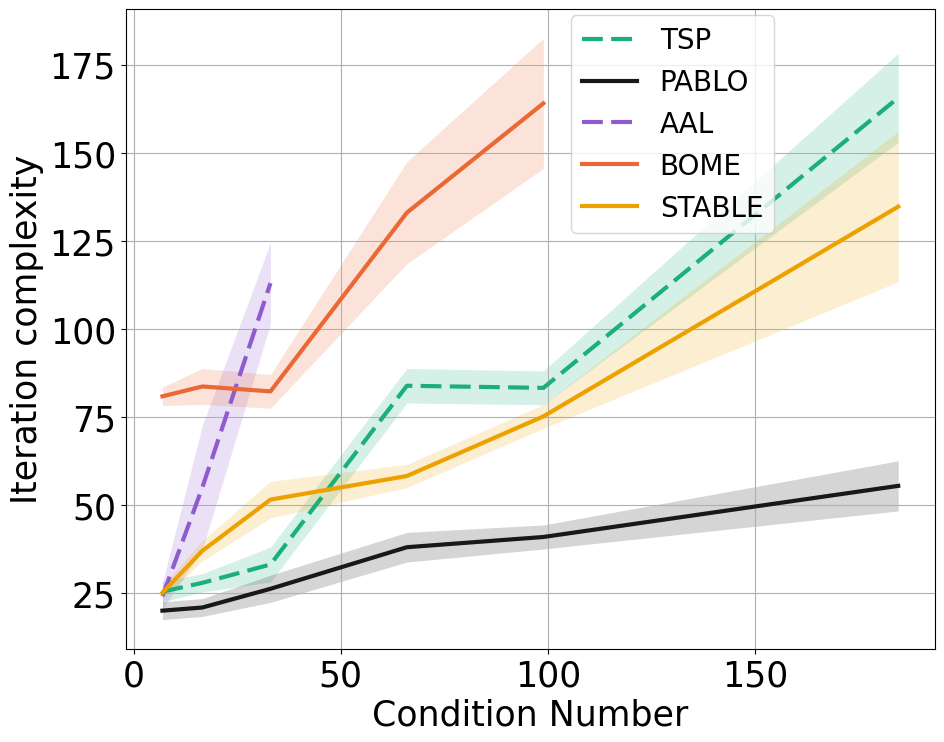

In [55]:
def block_reduce(vals, window: int, fn=np.nanmean) -> np.ndarray:
    vals = np.asarray(vals, dtype=float).ravel()
    pad_end = (-len(vals)) % window
    if pad_end:
        vals = np.append(vals, [vals[-1]] * pad_end)
    return fn(vals.reshape(-1, window), axis=1)

plt.rcParams.update({'font.size': 25})
fig, axes = plt.subplots(1, 1, figsize=(10,8))

ITER_COMP_TOL = 1e-2
saveplot = True

iter_comps = {}
ic_raw = {}
for kappa, seed_sweep in kappa_sweep.items():
    for seed, sweep_res in seed_sweep.items():
        # if seed>=5:
        #     continue
        for m, res in sweep_res.items():
            ic = IterComplexity(res['mean_excess_ll_loss'], res['mean_excess_ul_loss'], ITER_COMP_TOL)
            ic_raw.setdefault(m, {}).setdefault(kappa, []).append(ic)


iter_comps = {m: {kappa: np.nanmean(ics) for kappa, ics in ic_raw[m].items()} for m in ic_raw}

avg_iter_comps = {}
# average over seeds -> one (kappa, ic) pair per condition number
for m, per_kappa in ic_raw.items():
    kappas = sorted(per_kappa)
    avg_iter_comps[m] = {
        'kappa': np.array(kappas, dtype=float),
        'ic':    np.array([np.mean(per_kappa[k]) for k in kappas], dtype=float),
    }

BAND = 'std'
# NUM_SEEDS = 5
for m in METHODS:
    ks = np.fromiter(iter_comps[m].keys(),   float)
    vs = np.fromiter(iter_comps[m].values(), float)

    kappa_avg = block_reduce(ks, NUM_SEEDS, np.nanmean)
    ic_avg    = block_reduce(vs, NUM_SEEDS)

    if BAND == 'minmax':
        lo = block_reduce(vs, NUM_SEEDS, np.nanmin)
        hi = block_reduce(vs, NUM_SEEDS, np.nanmax)
    else:
        sd = block_reduce(vs, NUM_SEEDS, np.nanstd)
        lo, hi = ic_avg - sd, ic_avg + sd

    print(f'{m}: {ic_avg}, {sd}')
    axes.fill_between(kappa_avg, lo, hi, color=COLOURS[m],
                      alpha=0.18, linewidth=0, zorder=1)
    axes.plot(kappa_avg, ic_avg, label=m, color=COLOURS[m],
              linestyle=LINESTYLES[m], linewidth=3, zorder=3)
    # axes.scatter(ks, vs, color=COLOURS[m], marker='.', linewidth=2, zorder=2)
    
axes.legend(loc=(0.55,0.65), fontsize=20)
# axes.set_xscale('log')
# plt.yscale('log')
plt.grid(True)
axes.set_xlabel(r'Condition Number')
axes.set_ylabel('Iteration complexity')
plt.tight_layout()
# axes.set_yscale('log')
if saveplot:
    plt.savefig('RidgeRegression-Conditioning.png', dpi=300)
plt.show()

In [ ]:
# print(block_reduce(np.fromiter(iter_comps['PABLO'].values(), float), NUM_SEEDS)
# print(block_reduce(np.fromiter(iter_comps['STABLE'].values(), float), NUM_SEEDS)

[ 46.5  61.4  72.9  82.7  81.2 102.1]
[ 51.7  60.   78.4  88.3 116.9 203.9]
[  6.94100664  16.59000778  33.02159557  65.96062992  98.9117708
 184.59023588]


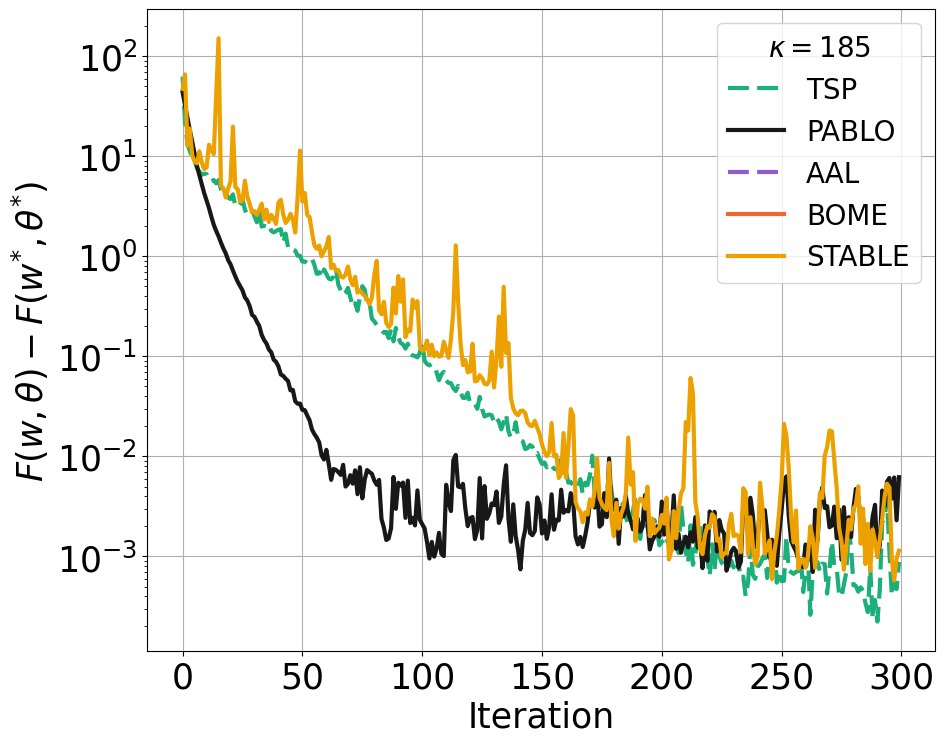

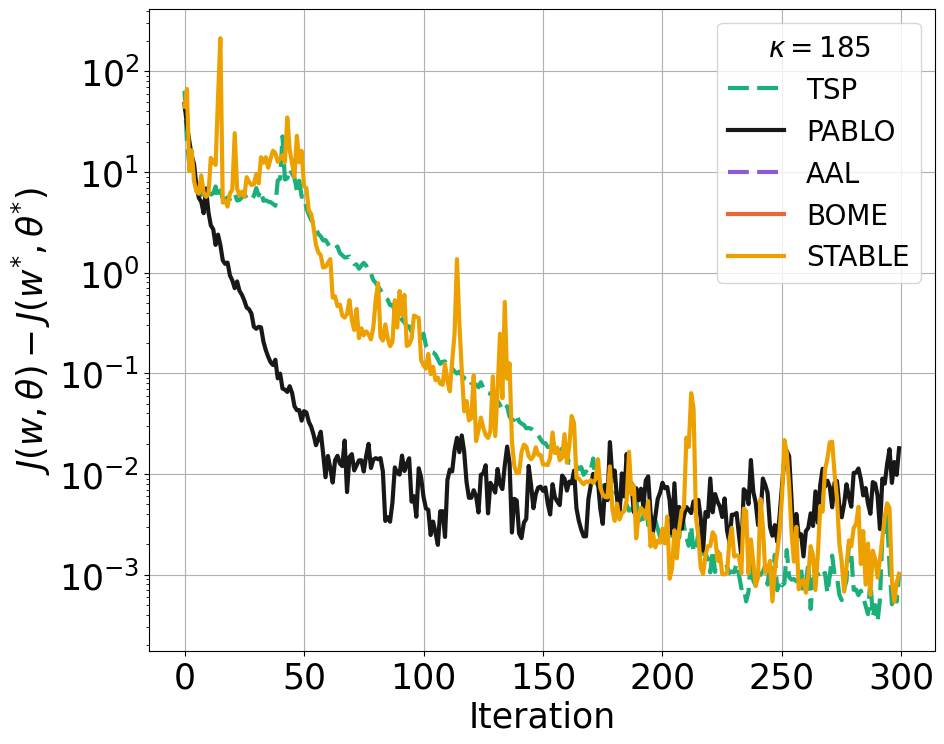

In [61]:
saveplot=True
KAPPA_IDX_TO_PLOT = 5


ul_runs, ll_runs = {}, {}
for idx, (kappa, seed_sweep) in enumerate(kappa_sweep.items()):
    g = idx // NUM_SEEDS          # consecutive NUM_SEEDS entries share the same h0
    for seed, sweep_res in seed_sweep.items():
        # if seed >= 5: continue
        for m, res in sweep_res.items():
            ul_runs.setdefault(g, {}).setdefault(m, []).append(res['mean_excess_ul_loss'])
            ll_runs.setdefault(g, {}).setdefault(m, []).append(res['mean_excess_ll_loss'])

avged_ul_results = {g: {m: np.mean(v, axis=0) for m, v in d.items()} for g, d in ul_runs.items()}
avged_ll_results = {g: {m: np.mean(v, axis=0) for m, v in d.items()} for g, d in ll_runs.items()}


plt.rcParams.update({'font.size': 25})
fig, ax = plt.subplots(1, 1, figsize=(10,8))
for m, curve in avged_ul_results[KAPPA_IDX_TO_PLOT].items():
    ax.semilogy(range(0,len(curve)), curve, label=m, color=COLOURS[m], linestyle=LINESTYLES[m], linewidth=3)
plt.rcParams.update({'font.size': 20})
ax.legend(title=f'$\kappa={int(round(kappa_avg[KAPPA_IDX_TO_PLOT])):d}$', fontsize=20,loc='upper right')
plt.rcParams.update({'font.size': 25})
ax.grid(True)
ax.set_ylabel(r'$F(w,\theta)-F(w^{*},\theta^{*})$')
ax.set_xlabel('Iteration')
# ax.set_xscale('log')
plt.tight_layout()
if saveplot:
    plt.savefig(f'RidgeRegression-F-kappa={kappa_avg[KAPPA_IDX_TO_PLOT]:.1f}.png', dpi=300)
plt.show()


fig, ax = plt.subplots(1, 1, figsize=(10, 8))
for m, curve in avged_ll_results[KAPPA_IDX_TO_PLOT].items():
    ax.semilogy(range(0,len(curve)),curve, label=m, color=COLOURS[m], linestyle=LINESTYLES[m], linewidth=3)

plt.rcParams.update({'font.size': 20})
ax.legend(title=f'$\kappa={int(round(kappa_avg[KAPPA_IDX_TO_PLOT])):d}$', fontsize=20,)#loc='lower left')
plt.rcParams.update({'font.size': 25})
ax.grid(True)
ax.set_ylabel(r'$J(w,\theta)-J(w^{*},\theta^{*})$')
ax.set_xlabel('Iteration')
# ax.set_xscale('log')
# ax.set_ylim([5e-4, 15])
plt.tight_layout()
if saveplot:
    plt.savefig(f'RidgeRegression-J-kappa={kappa_avg[KAPPA_IDX_TO_PLOT]:.1f}.png', dpi=300)
plt.show()
    



In [195]:
print(np.mean(avged_ll_results[KAPPA_IDX_TO_PLOT]['PABLO'][-100:]))
print(np.mean(avged_ll_results[KAPPA_IDX_TO_PLOT]['STABLE'][-100:]))

0.14501323658643137
0.033975314322276975


In [300]:
for m, ts in avg_times.items():
    print(f'{m}:\n\t AVG/SWEEP(ms): {np.mean(ts)*1000:.2f}+-{np.std(ts)*1000:.3f}\n\t AVG/ITER(us): {1e6*np.mean(ts)/(N_GRID*N_GRID*N_ITERS):.2f}+-{1e6*np.std(ts)/(N_GRID*N_GRID*N_ITERS):.2f}')

TSP:
	 AVG/SWEEP(ms): 970.67+-34.394
	 AVG/ITER(us): 359.51+-12.74
PABLO:
	 AVG/SWEEP(ms): 1196.41+-45.433
	 AVG/ITER(us): 443.11+-16.83
AAL:
	 AVG/SWEEP(ms): 730.83+-26.822
	 AVG/ITER(us): 270.68+-9.93
BOME:
	 AVG/SWEEP(ms): 2092.28+-58.284
	 AVG/ITER(us): 774.92+-21.59
STABLE:
	 AVG/SWEEP(ms): 3298.72+-83.185
	 AVG/ITER(us): 1221.75+-30.81


{np.float64(7.173599809334763): np.float64(41.0), np.float64(6.641045419531889): np.float64(43.0), np.float64(6.574108389049491): np.float64(67.0), np.float64(17.602051522479297): np.float64(41.0), np.float64(16.20561479720993): np.float64(46.0), np.float64(15.802892233783117): np.float64(41.0), np.float64(35.04622742619671): np.float64(46.0), np.float64(32.29627258082241): np.float64(58.0), np.float64(31.443058500586176): np.float64(43.0), np.float64(69.99394436884823): np.float64(91.0), np.float64(64.57999219323814): np.float64(91.0), np.float64(62.78587399328522): np.float64(96.0), np.float64(104.93698368062817): np.float64(132.0), np.float64(96.91138991763759): np.float64(143.0), np.float64(94.12828766151858): np.float64(101.0)}
{np.float64(7.173599809334763): np.float64(51.0), np.float64(6.641045419531889): np.float64(55.0), np.float64(6.574108389049491): np.float64(44.0), np.float64(17.602051522479297): np.float64(43.0), np.float64(16.20561479720993): np.float64(51.0), np.float64

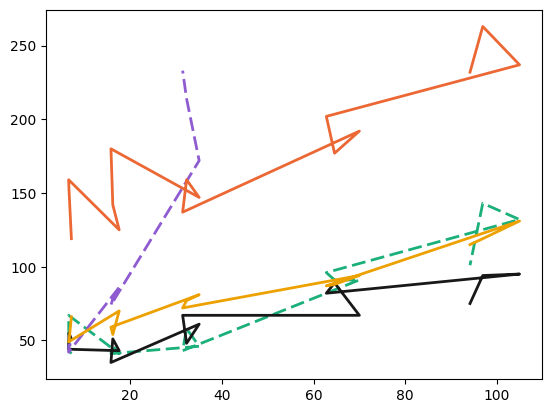

In [38]:
for m in METHODS:
    print(iter_comps[m])
    plt.plot(iter_comps[m].keys(), iter_comps[m].values(), label=m, color=COLOURS[m], linestyle=LINESTYLES[m],
                linewidth=2)

[np.float64(5.467967650943753), np.float64(26.208993053601013), np.float64(31.440020517835993), np.float64(39.28923014653909)]


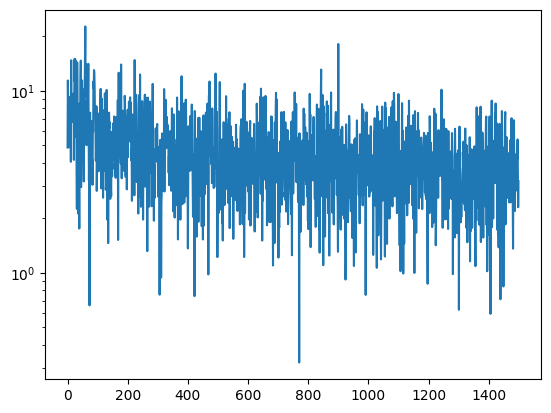

In [66]:
kappas = list(kappa_sweep.keys())
print(kappas)
plt.semilogy(kappa_sweep[kappas[0]][0]['AAL']['mean_ul_loss'])

____
### TUNING
___
___

In [ ]:
LOW = -2
HIGH = 2
N_GRID = 3
N_ITERS = 80
BATCH_SIZE = 10
w0_N = 2
th0_HIGH = 2
th0_LOW = -2
ITER_COMP_TOL = 1e-2
SEED=0


m = 'STABLE'
HPARAMS = {
        # "BOME": {'opt': "sgdm",'inner_steps': 10,'inner_lr': 0.03940, 'eta': 0.6869,'lr_w': 0.01777, 'lr_theta': 0.01457, 'barrier': "grad_norm"},
        # 'PABLO': {'lr_w': 0.0055, 'lr_theta': 0.012, 'alpha': 0.999, 'eps': 1e-6, 
        #                                 'rho': 0.03, 'lr_lambda': 0.00506, 'tau':1, 'y_rate': 0.1, 'grad_clip': 5, 
        #                                 'lambda_bound': 0.008,},
        "TSP": dict(alpha=2.4, eta=0.05,tau=0.0001,gamma=0.07, delta=0.0, p=0.001, mu=.05, 
                                            theta=0.05, omega=0.4, lambda_init=0.08, beta=0.075),
        "STABLE":   dict(lr_w=0.125, lr_theta=0.047, tau=0.45, mu_g=1.5, C_gxy=1000),
        # 'AAL': { 'rho0': 0.03, 'alpha': 1e-5, 'eps': 1e-6, 't': 100, 'tau': 0.03, },
        # "BOME": dict(opt="sgdm", inner_steps=10, inner_lr=0.01, eta=1.36, lr_w=0.013, lr_theta=0.0037, barrier="grad_norm")
}



# dict(alpha=0.001, eta=0.001,tau=0.001,gamma=2, delta=0.0, p=1,mu=.9, theta=0.9, omega=0.9, lambda_init=0.1)
RUN_KWARGS = dict(num_iters=N_ITERS,data=data, batch_size=BATCH_SIZE, w0_N=N_GRID, th0_N=N_GRID, th0_high=th0_HIGH,th0_low=th0_LOW, seed=SEED)

# TUNED: tau, alpha, eps,rho0
# param_ranges = np.logspace(np.log10(2), np.log10(10), 8)
# param_ranges = np.logspace(np.log10(0.1), np.log10(0.9), 8)
param_ranges = np.linspace(0.03, 0.06, 8)
# param_ranges = np.linspace(0.01, 0.08, 8)
num_seeds = 5
# meanj = []
for seed in range(num_seeds):
        print(f'Seed:{seed}')
        H = np.eye(M,M)
        H[0,0] = 1
        data = make_data(feature_cov=H,feature_dim=M,noise_var=NOISE_VAR,N_train=N_TRAIN, N_val=N_VAL,
                        w_true=W_TRUE,seed=seed)
        RUN_KWARGS = dict(num_iters=N_ITERS,data=data, batch_size=BATCH_SIZE,
                        w0_N=N_GRID, th0_N=N_GRID, th0_high=th0_HIGH,th0_low=th0_LOW, seed=seed)
        
        for param in ['lr_theta']:

                best_hparam = tune_single(method=m, hparams=HPARAMS, param_name=param,force_converge=True, 
                        param_range=param_ranges, **RUN_KWARGS, verbose=False)
                # HPARAMS[m][param] = best_hparam


        res = run_sweep(m, HPARAMS,**RUN_KWARGS)
        # plt.semilogy(res['mean_ul_loss'])
        # plt.semilogy(res['mean_ll_loss'])
        # plt.plot([0,len(res['mean_ll_loss'])],[2e-2,2e-2],'-k')
        # meanj.append(np.mean(res['mean_ll_loss'][-30:]))
        # print(f"J: {np.mean(res['mean_ll_loss'][-30:])*1000:.3f}")
        # print(f"F: {np.mean(res['mean_ul_loss'][-30:])*1000:.3f}")
        plt.show()
# print(np.nanmean(meanj))

Seed:0
  tuning lr_theta ...
    lr_theta=0.03  iter_comp=38  auc=-3.618  best=0.03
    lr_theta=0.034286  iter_comp=33  auc=-3.871  best=0.03428571428571429
    lr_theta=0.038571  iter_comp=31  auc=-3.976  best=0.03857142857142857
    lr_theta=0.042857  iter_comp=30  auc=-4.122  best=0.04285714285714286
    lr_theta=0.047143  iter_comp=26  auc=-4.280  best=0.04714285714285714
    lr_theta=0.051429  iter_comp=24  auc=-4.419  best=0.05142857142857143
    lr_theta=0.055714  iter_comp=23  auc=-4.469  best=0.055714285714285716
    lr_theta=0.06  iter_comp=25  auc=-4.308  best=0.055714285714285716
    → lr_theta = 0.055714285714285716  (score=23)
STABLE: 9 runs
0 / 9 runs diverged and excluded
Seed:1
  tuning lr_theta ...
    lr_theta=0.03  iter_comp=37  auc=-3.494  best=0.03
    lr_theta=0.034286  iter_comp=35  auc=-3.667  best=0.03428571428571429
    lr_theta=0.038571  iter_comp=30  auc=-3.889  best=0.03857142857142857
    lr_theta=0.042857  iter_comp=29  auc=-4.032  best=0.04285714285714

/var/folders/__/2mvsq34s3bd08fm5gjkdlnvw0000gp/T/ipykernel_491/570413099.py:63: RuntimeWarning: invalid value encountered in matmul
  J = np.mean((Xt@w - yt)**2) + th*(w.T@w).item()
/var/folders/__/2mvsq34s3bd08fm5gjkdlnvw0000gp/T/ipykernel_491/570413099.py:64: RuntimeWarning: invalid value encountered in matmul
  F_ = np.mean((Xv@w - yv)**2)


    lr_theta=0.06  ERROR: STABLE: H_yy holds NaN/Inf before the PSD projection -- the iterates have diverged. Reduce lr_theta/lr_w, or raise mu_g: the correction term H_yy^{-1} H_xy^T dx scales like 1/mu_g.
    → lr_theta = 0.04285714285714286  (score=24)
STABLE: 9 runs


FloatingPointError: STABLE: H_yy holds NaN/Inf before the PSD projection -- the iterates have diverged. Reduce lr_theta/lr_w, or raise mu_g: the correction term H_yy^{-1} H_xy^T dx scales like 1/mu_g.

In [ ]:
LOW = -2
HIGH = 2
N_GRID = 3
N_ITERS = 700
BATCH_SIZE = 10
w0_N = 2
th0_HIGH = 2
th0_LOW = -2
ITER_COMP_TOL = 1e-2
# SEED=0


m = 'TSP'
HPARAMS = {
         "TSP": dict(alpha=0.65, eta=0.0089,tau=0.0001,gamma=0.074, delta=0.0, p=0.0001, mu=.05, 
                                                    theta=0.05, omega=0.4, lambda_init=0.08, beta=0.011),
        # 'AAL': { 'rho0': 0.03, 'alpha': 1e-5, 'eps': 1e-6, 't': 100, 'tau': 0.03, },
        # "BOME": dict(opt="sgdm", inner_steps=10, inner_lr=0.01, eta=1.36, lr_w=0.013, lr_theta=0.0037, barrier="grad_norm")
}

for seed in range(NUM_SEEDS):
    H = np.eye(M,M)
    H[0,0] = 56
    data = make_data(feature_cov=H,feature_dim=M,noise_var=NOISE_VAR,N_train=N_TRAIN, N_val=N_VAL,
                    w_true=W_TRUE,seed=SEED)
    RUN_KWARGS = dict(num_iters=N_ITERS,data=data, batch_size=BATCH_SIZE,
                    w0_N=N_GRID, th0_N=N_GRID, th0_high=th0_HIGH,th0_low=th0_LOW, seed=SEED)

    # dict(alpha=0.001, eta=0.001,tau=0.001,gamma=2, delta=0.0, p=1,mu=.9, theta=0.9, omega=0.9, lambda_init=0.1)
    RUN_KWARGS = dict(num_iters=N_ITERS,data=data, batch_size=BATCH_SIZE, w0_N=N_GRID, th0_N=N_GRID, th0_high=th0_HIGH,th0_low=th0_LOW, seed=SEED)

    # TUNED: tau, alpha, eps,rho0
    # param_ranges = np.logspace(np.log10(2), np.log10(10), 8)
    # param_ranges = np.logspace(np.log10(1-6), np.log10(1e-1), 10)
    param_ranges = np.linspace(0.6, 0.75, 8)
    for param in ['alpha']:

            best_hparam = tune_single(method=m, hparams=HPARAMS, param_name=param,force_converge=True, 
                    param_range=param_ranges, **RUN_KWARGS, verbose=False)
            HPARAMS[m][param] = best_hparam


res = run_sweep(m, HPARAMS,**RUN_KWARGS)
plt.semilogy(res['mean_ul_loss'])
plt.semilogy(res['mean_ll_loss'])


PABLO: 4 runs
0 / 4 runs diverged and excluded
PABLO: 4 runs
0 / 4 runs diverged and excluded
PABLO: 4 runs
0 / 4 runs diverged and excluded
-13.33672550120367
-750.6100779149233


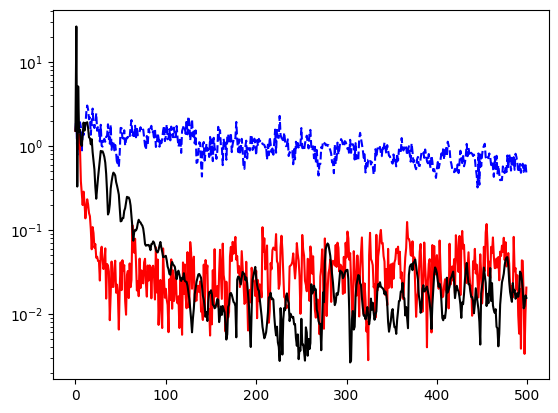

In [127]:

h = copy.deepcopy(HPARAMS)
h['PABLO']['lr_w'] = 0.001
r1 = run_sweep('PABLO', h,**RUN_KWARGS)
h['PABLO']['lr_w'] = 0.01
r2 = run_sweep('PABLO', h,**RUN_KWARGS)
h['PABLO']['lr_w'] = 0.1
r3 = run_sweep('PABLO', h,**RUN_KWARGS)
# h['PABLO']['lr_w'] = 10
# r2 = run_sweep('PABLO', h,**RUN_KWARGS)

plt.semilogy(r1['mean_ll_loss'],'--b')
plt.semilogy(r2['mean_ll_loss'],'-r')
plt.semilogy(r3['mean_ll_loss'],'-k')
print(np.sum(np.log10(r1['mean_ll_loss'].clip(min=1e-16))))
print(np.sum(np.log10(r2['mean_ll_loss'].clip(min=1e-16))))

# Conditioning Scaling Problem Plot

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from blo_optimisers import *
from typing import Dict
import copy
import pickle
import matplotlib
from functools import partial
import timeit

class LinearModel(nn.Module):
    """Simple neural network for demonstration"""
    def __init__(self, input_dim=10, output_dim=1, initial_weights:torch.Tensor=None, seed:int=None):
        super().__init__()
        if seed is not None:
            torch.manual_seed(seed)
        self.fc1 = nn.Linear(input_dim, output_dim,bias=False)
        with torch.no_grad():
            if initial_weights is not None:
                self.fc1.weight.copy_(initial_weights)
    
    def forward(self, x):
        return self.fc1(x)

class ScalarModule(nn.Module):
    def __init__(self, value=1.0):
        super().__init__()
        self.value = nn.Parameter(torch.tensor(float(value)))
    def forward(self):
        return self.value


def run_single(method, hparams:dict, w0, th0,
               num_iters,data,batch_size:int=1, seed:int=0):
    
    optimiser = build_optimiser(method, w0, th0,hparams)

    ll_loss = []
    ul_loss = []
    excess_ll_loss = []
    excess_ul_loss = []

    # full-data arrays for evaluating excess losses at each iterate
    Xt, yt = data['X_train'].double().numpy(), data['y_train'].double().numpy()
    Xv, yv = data['X_val'].double().numpy(),   data['y_val'].double().numpy()
    lam_min_Ht = np.linalg.eigvalsh(Xt.T@Xt/len(yt)).min()

    _,_, ul_min, _ = BilevelRidgeProblemOptimalSolution(data, verbose=False)
    ul_min = float(ul_min)

    for iter in range(num_iters):
        data_point = data_batch(data, batch_size=batch_size,seed=seed+iter)
        res = optimiser.step(data_point)
        ll_loss.append(res['ll_loss'])
        ul_loss.append(res['ul_loss'])

        # current iterate (w0/th0 are updated in place by every optimiser)
        w = w0.fc1.weight.detach().double().numpy().T
        th = th0.value.item()
        J = np.mean((Xt@w - yt)**2) + th*(w.T@w).item()
        F_ = np.mean((Xv@w - yv)**2)

        # LL has no minimum when Ht + th*I is not positive definite
        if th > -lam_min_Ht:
            _, ll_min = SingleLevelRidgeProblemOptimalSolution(data, th)
            excess_ll_loss.append(J - float(ll_min))
        else:
            excess_ll_loss.append(np.nan)
        excess_ul_loss.append(F_ - ul_min)
    return {'ll_loss': ll_loss, 'ul_loss': ul_loss, 'excess_ul_loss':excess_ul_loss, 'excess_ll_loss': excess_ll_loss}


def run_sweep(method,hparams:dict,num_iters,data,
              th0_low, th0_high, th0_N,
              w0_N, batch_size:int=1, seed:int=0,verbose=True): 

    if verbose:
        print(f'{method}: {th0_N*w0_N} runs')
    results = {'history_ll_loss': [],'history_ul_loss': [],'history_excess_ll_loss': [],'history_excess_ul_loss': []}
    for th_val in np.linspace(th0_low, th0_high, th0_N):
        for w0_seed in range(w0_N):

            th0 = ScalarModule(th_val)
            w0 = LinearModel(input_dim=M,seed=seed+w0_seed)
            res = run_single(method, hparams,w0, th0, num_iters=num_iters,data=data, batch_size=batch_size )
            results['history_ll_loss'].append(res['ll_loss'])
            results['history_ul_loss'].append(res['ul_loss'])
            results['history_excess_ll_loss'].append(res['excess_ll_loss'])
            results['history_excess_ul_loss'].append(res['excess_ul_loss'])

    ul = np.array(results['history_ul_loss'])                        
    ll = np.array(results['history_ll_loss'])                        
    excess_ul = np.array(results['history_excess_ul_loss'])
    excess_ll = np.array(results['history_excess_ll_loss'])
    valid = np.all(np.isfinite(ul), axis=1)
    if verbose:
        print(f'{(~valid).sum()} / {len(valid)} runs diverged and excluded') 
    results['n_diverged'] = int((~valid).sum())    
    results['median_ul_loss'] = np.median(np.abs(ul[valid]),0)
    results['median_ll_loss'] = np.median(np.abs(ll[valid]),0)
    results['mean_ll_loss'] = np.mean(np.abs(ll[valid]),0)
    results['mean_ul_loss'] = np.mean(np.abs(ul[valid]),0)
    # nan-aware: excess LL is nan while theta <= -lambda_min(Ht)
    results['median_excess_ul_loss'] = np.nanmedian(np.abs(excess_ul[valid]),0)
    results['median_excess_ll_loss'] = np.nanmedian(np.abs(excess_ll[valid]),0)
    results['mean_excess_ll_loss'] = np.nanmean(np.abs(excess_ll[valid]),0)
    results['mean_excess_ul_loss'] = np.nanmean(np.abs(excess_ul[valid]),0)
    return results


def ScoreCurve(results, window:int=100)->float:
    ll = np.asarray(results['mean_excess_ll_loss'])
    ul = np.asarray(results['mean_excess_ul_loss'])
    auc = np.mean(np.log10(ll.clip(1e-16))) + np.mean(np.log10(ul.clip(1e-16)))
    mask = (ll < ITER_COMP_TOL) & (ul < ITER_COMP_TOL)
    iter_comp = int(np.argmax(mask)) if mask.any() else None
    return iter_comp, auc


def RidgeProblemConditionNumber(H, w0):
    z = np.zeros_like(w0)
    KKT_mat = np.block([[H,z,H],[z.T, 0, w0.T],[H,w0, z@z.T]])
    return np.linalg.cond(KKT_mat)

def SingleLevelRidgeProblemOptimalSolution(data,theta0:float, verbose:bool=False):

    _, M = data['X_train'].shape
    Nt = len(data['y_train'])
    Ht =( 1/Nt*data['X_train'].T@data['X_train']).detach().numpy()
    rt = ( 1/Nt*data['X_train'].T@data['y_train']).detach().numpy()

    w0 = np.linalg.inv(Ht+theta0*np.eye(M,M))@rt

    Xt, yt = data['X_train'].numpy(), data['y_train'].numpy()
    ll_min = np.mean((Xt@w0 - yt)**2) + theta0*(w0.T@w0).item()

    return w0, ll_min

def BilevelRidgeProblemOptimalSolution(data, verbose:bool=False):

    Nt, Nv = [len(data['y_train']), len(data['y_val'])]
    _, M = data['X_train'].shape


    Ht =( 1/Nt*data['X_train'].T@data['X_train']).detach().numpy()
    Hv =(1/Nv*data['X_val'].T@data['X_val']).detach().numpy()
    rt = ( 1/Nt*data['X_train'].T@data['y_train']).detach().numpy()
    rv =  (1/Nv*data['X_val'].T@data['y_val']).detach().numpy()

    # print(Ht.type(), rt.type())
    th0 = sum(rt-Ht@np.linalg.inv(Hv)@rv)/sum(np.linalg.inv(Hv)@rv)
    w0 = np.linalg.inv(Hv)@rv

    Xt, yt = data['X_train'].numpy(), data['y_train'].numpy()
    Xv, yv = data['X_val'].numpy(), data['y_val'].numpy()
    ll_min = np.mean((Xt@w0 - yt)**2) + th0.item()*(w0.T@w0).item()
    ul_min = np.mean((Xv@w0 - yv)**2)

    assert (w0>0).all() # solution set based on assumption w*>0 

    feasibility_constraint = sum(np.abs((Ht+th0*np.eye(M,M))@w0-rt))

    if verbose:
        print(f'Solved parameters:\n\ttheta*:{th0}\n\tw*: {w0.T}')
        print(f'\t constraint error: {feasibility_constraint[0]}')

    return w0, th0, ul_min, ll_min

def BilevelRidgeProblemConditionNumberTrue(data, verbose:bool=False):

    Nt, Nv = [len(data['y_train']), len(data['y_val'])]
    _, M = data['X_train'].shape


    Ht =( 1/Nt*data['X_train'].T@data['X_train']).detach().numpy()
    Hv =(1/Nv*data['X_val'].T@data['X_val']).detach().numpy()

    w0, th0,_,_ = BilevelRidgeProblemOptimalSolution(data, verbose)

    assert (w0>0).all() # solution set based on assumption w*>0 

    
    z = np.zeros_like(w0)
    KKT_mat = np.block([[Hv,z,Ht+th0*np.eye(M,M)],[z.T, 0, w0.T],[Ht+th0*np.eye(M,M),w0, z@z.T]])
    cond_no = np.linalg.cond(KKT_mat)
    if verbose:
        print(f'\t KKT condition no.: {cond_no}')

    return cond_no

# def tune_single(method,hparams:dict, param_name, param_range, num_iters,data,
#         th0_low, th0_high, th0_N,
#         w0_N, batch_size:int=1, seed:int=0,verbose=True):

#     best_hparam = None
#     best_score = np.inf
#     best_iter_comp = None
#     best_auc = np.inf
#     print(f'Tuning {param_name}')
#     for param_val in param_range:
#         hparams[method][param_name] = param_val
#         res = run_sweep(method, hparams, num_iters=num_iters,data=data, 
#                         batch_size=batch_size, w0_N=w0_N, 
#                         th0_N=th0_N, th0_high=th0_high, th0_low=th0_low, seed=seed,verbose=False)
#         iter_comp, auc = ScoreCurve(res)
#         if iter_comp is not None:
#               if best_iter_comp is None or iter_comp < best_iter_comp:
#                   best_iter_comp = iter_comp
#                   best_hparam = param_val
#               score_str = f'iter_comp={iter_comp}'
#         else:
#             if best_iter_comp is None and auc < best_auc:
#                 best_auc = auc
#                 best_hparam = param_val
#             score_str = f'auc={auc:.3f}'

#         if verbose:
#             print(f'\t {param_name}={param_val} {score_str} best=({best_hparam})')

#     best_score = best_iter_comp if best_iter_comp is not None else best_auc
#     print(f'\tbest=({best_hparam}) score:{best_score}')

#     return best_hparam, best_score
def IterComplexity(J, F, tol):
    J_iter = np.argmax(J<tol)
    F_iter = np.argmax(F<tol)
    if (not J_iter) or (not F_iter):
        return np.nan
    return np.max([J_iter, F_iter])

def tune_single(method, hparams, param_name, param_range,force_converge:bool=False, **run_kwargs):
    best_hparam, best_iter_comp, best_auc_at_best_ic, best_auc = None, None, np.inf, np.inf
    print(f'  tuning {param_name} ...', flush=True)
    for val in param_range:
        hparams[method][param_name] = val
        try:
            res = run_sweep(method, hparams, **run_kwargs)
            ic, auc = ScoreCurve(res)
            if force_converge and res['n_diverged']>0:
                print(f'    {param_name}={val:.5g}  n_diverged: {res["n_diverged"]}', flush=True)
                continue
        except Exception as e:
            print(f'    {param_name}={val:.5g}  ERROR: {e}', flush=True)
            continue
        if ic is not None:
            # tie-break on auc when iter_comp is equal
            if best_iter_comp is None or ic < best_iter_comp or (ic == best_iter_comp and auc < best_auc_at_best_ic):
                best_iter_comp, best_auc_at_best_ic, best_hparam = ic, auc, val
            score_str = f'iter_comp={ic}  auc={auc:.3f}'
        else:
            if best_iter_comp is None and auc < best_auc:
                best_auc, best_hparam = auc, val
            score_str = f'auc={auc:.3f}' if auc is not None else  f'auc=NONE'
        print(f'    {param_name}={val:.5g}  {score_str}  best={best_hparam}', flush=True)
    best_score = best_iter_comp if best_iter_comp is not None else best_auc
    print(f'    → {param_name} = {best_hparam}  (score={best_score})', flush=True)
    return best_hparam


device=torch.device("cpu")   
SGD_MOMENTUM = partial(torch.optim.SGD, momentum=0.9)

def build_optimiser(method, w0, th0, hparams):
    h = hparams[method]
    common = dict(ll_model=w0, ul_model=th0, lower_loss_fn=lower_loss, upper_loss_fn=upper_loss,
                  stochastic=False, device=device)

    if method == "PABLO":
        rms = {"alpha": h["alpha"]}
        return BLO_optimiser_PABLO_Prox_Bound(**common,
            w_optimiser=torch.optim.RMSprop, theta_optimiser=torch.optim.RMSprop, lambda_optimiser=torch.optim.SGD,
            w_optimiser_kwargs=rms, theta_optimiser_kwargs=rms,
            lr_w=h["lr_w"], lr_theta=h["lr_theta"], rho=h["rho"], lr_lambda=h["lr_lambda"],
            tau=h["tau"], gamma=h["y_rate"] / h["tau"], lambda_bound=h["lambda_bound"], grad_clip=h["grad_clip"],
            warmup_ratio=h.get("warmup_ratio", None), total_steps=h.get("total_steps",None))

    if method == "BOME":
        bome_opt = {"sgdm": SGD_MOMENTUM, "adam": torch.optim.Adam, "rmsprop": torch.optim.RMSprop}[h.get("opt", "sgdm")]
        return BLO_optimiser_BOME(**common, inner_steps=h["inner_steps"], inner_lr=h["inner_lr"], eta=h["eta"],
            lr_w=h["lr_w"], lr_theta=h["lr_theta"], w_optimiser=bome_opt, theta_optimiser=bome_opt,
            barrier=h["barrier"])

    if method == "TSP":
        return BLO_optimiser_TSP(**common, **h)

    if method == "STABLE":
            return BLO_optimiser_STABLE(**common, **h)

    if method == "AID":
        return BLO_optimiser_AID_Neumann(**common, **h)

    if method == "AAL":
        return BLO_optimiser_AAL(**common, **h)

    if method == "PBGD-Free":
        return BLO_optimiser_PBGD_Free(**common, **h)

    raise ValueError(f"unknown method: {method}")

def data_batch(data, batch_size, seed) -> dict[str, torch.Tensor]:
    rng_train = torch.Generator().manual_seed(seed)
    idx_t = torch.randperm(data['X_train'].shape[0], generator=rng_train)[:batch_size]
    rng_val = torch.Generator().manual_seed(seed)
    idx_v = torch.randperm(data['X_val'].shape[0], generator=rng_val)[:batch_size]
    return {'X_train': data['X_train'][idx_t],
            'y_train': data['y_train'][idx_t],
            'X_val': data['X_val'][idx_v],
            'y_val': data['y_val'][idx_v],}


def make_data(feature_cov:np.ndarray, 
              feature_dim:int, 
                noise_var:float, 
                w_true:np.ndarray,
                N_val:int, N_train:int,seed:int) -> dict[str, torch.Tensor]:

    if w_true is None:
        w_true = np.ones([feature_dim,1])
    w_true = np.asarray(w_true, dtype=np.float64)

    rng = np.random.default_rng(seed)

    X_train = rng.multivariate_normal(np.zeros(feature_dim), feature_cov, size=N_train)
    y_train = X_train@w_true + noise_var*rng.random((N_train,1))

    X_val= rng.multivariate_normal(np.zeros(feature_dim), feature_cov, size=N_val)
    y_val = X_val@w_true + noise_var*rng.random((N_val,1))
   
    return {
        'X_train': torch.tensor(X_train, dtype=torch.float32),
        'y_train': torch.tensor(y_train, dtype=torch.float32),
        'X_val':   torch.tensor(X_val, dtype=torch.float32),
        'y_val':   torch.tensor(y_val, dtype=torch.float32),
    }


COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AID": "#3b7dd8", "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}




In [8]:

c_bs = []
c_ss = []
c_b2 = []

for seed in range(1000000):
    M=5
    # w_true = np.random.randn(M,1)+2
    w_true = np.random.uniform(0.5,10, size=[M,1])
    w_true[w_true<0.1] = 0.1
    # feature_cov = np.diag(10**(np.random.uniform(low=0, high=1,size=M)))
    feature_cov = np.diag(np.random.uniform(low=1e-6, high=100,size=M))
    noise_var = 0.5

    # print(feature_cov)
    # print(w_true)
    data = make_data(feature_cov, M, noise_var=noise_var, w_true=w_true, N_val=1000, N_train=1000, seed=seed)

    c_bs.append(BilevelRidgeProblemConditionNumberTrue(data, verbose=False))
    cs = np.linalg.cond(feature_cov)
    c_ss.append(cs)




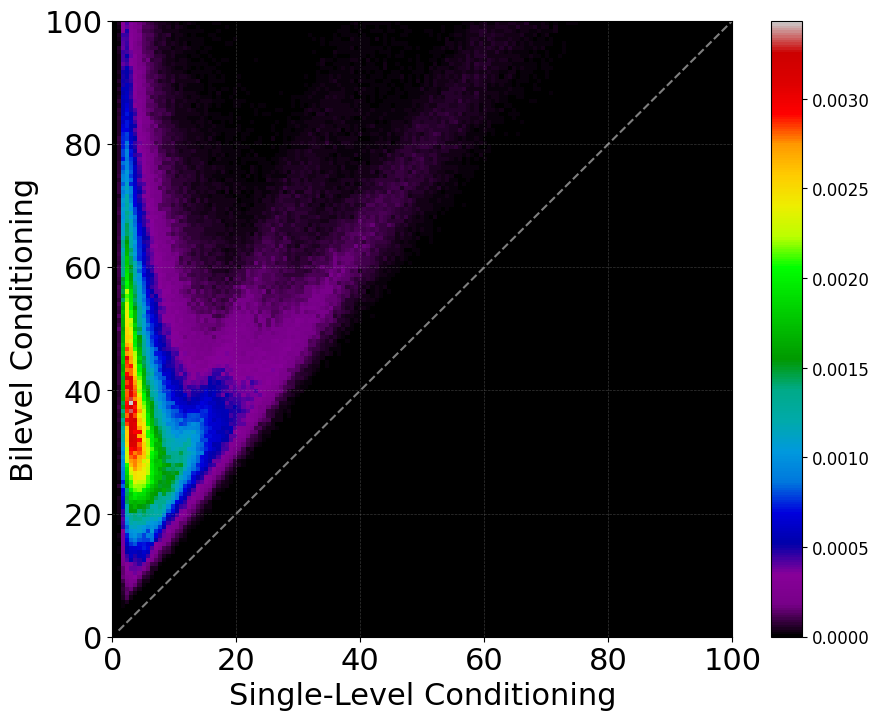

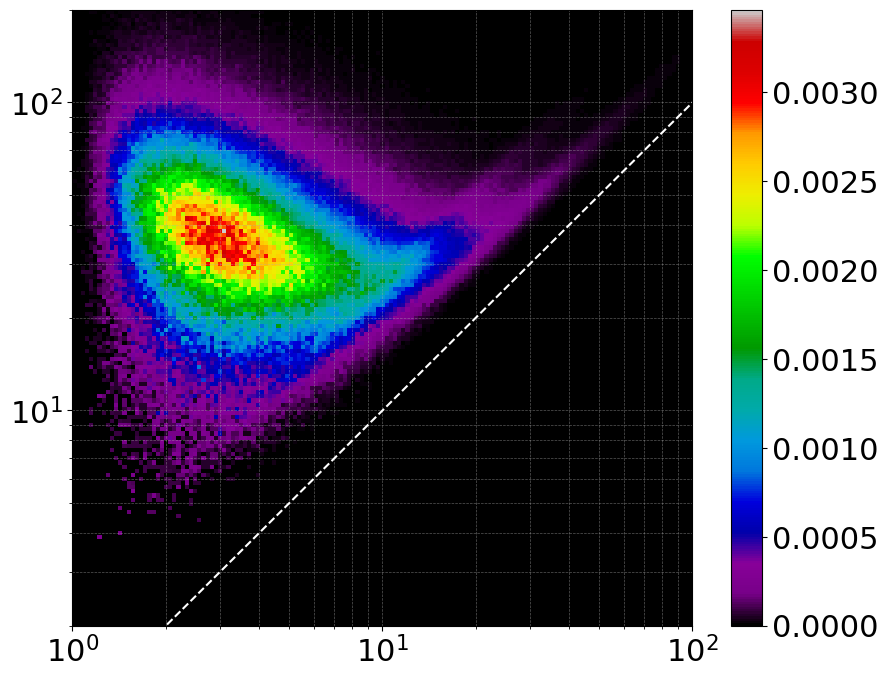

In [ ]:
import matplotlib.colors as mcolors
import matplotlib

saveplot = True
cmap = matplotlib.colormaps.get_cmap('nipy_spectral')

num_bins = 150
bin_lim = 100
plt.rcParams.update({'font.size': 22})
fig, ax = plt.subplots(1, 1, figsize=(10,8))
# ax.hist2d(np.log10(c_ss),np.log10(c_bs), bins=np.linspace(0,5,100), density=True)
_, _, _, im= ax.hist2d(c_ss,c_bs, bins=[np.linspace(0,bin_lim,num_bins),np.linspace(0,bin_lim,num_bins)],density=True, cmap=cmap)
# ax.set_xlim([0,3])
# ax.set_xlim([0,3])
ax.plot([1e0,1e6],[1e0,1e6],'--',color='w', alpha=0.5)
ax.set_xlabel('Single-Level Conditioning')
ax.set_ylabel('Bilevel Conditioning')
plt.rcParams.update({'font.size': 12})
fig.colorbar(im)
plt.rcParams.update({'font.size': 22})
ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.3) 
if saveplot:
    plt.savefig('SingleAndBilevelConditioning-Ridge.png', dpi=300)
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10,8))
  
bins=[np.logspace(np.log10(1),np.log10(bin_lim), num_bins), np.logspace(np.log10(1*2), np.log10(bin_lim*2), num_bins)] 
_, _, _, im = ax.hist2d(c_ss, c_bs, bins=bins,density=True, cmap=cmap)                      
fig.colorbar(im, ax=ax)
ax.set_xscale('log')                          
ax.set_yscale('log')                          
ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.5) 
# ax.hist2d(np.log10(c_ss),np.log10(c_bs), bins=np.linspace(0,2.5,100), density=True, cmap=cmap)
# # ax.set_xlim([0,3])
# # ax.set_xlim([0,3])
ax.plot([0,1e6],[0,1e6],'--',color='w')
if saveplot:
    plt.savefig('SingleAndBilevelConditioning-Ridge-log.png', dpi=300)
plt.show()

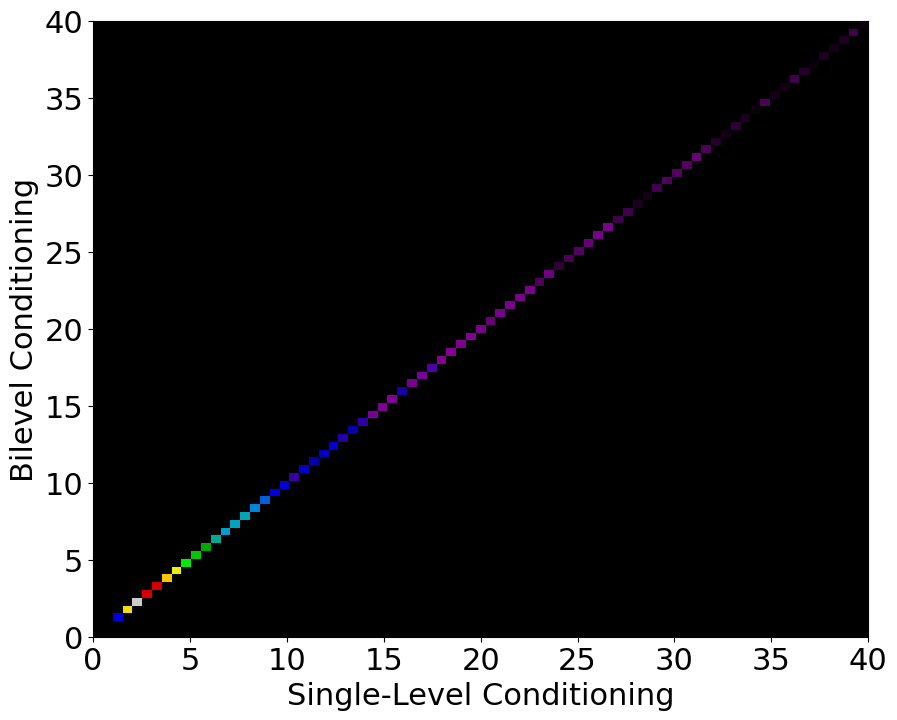

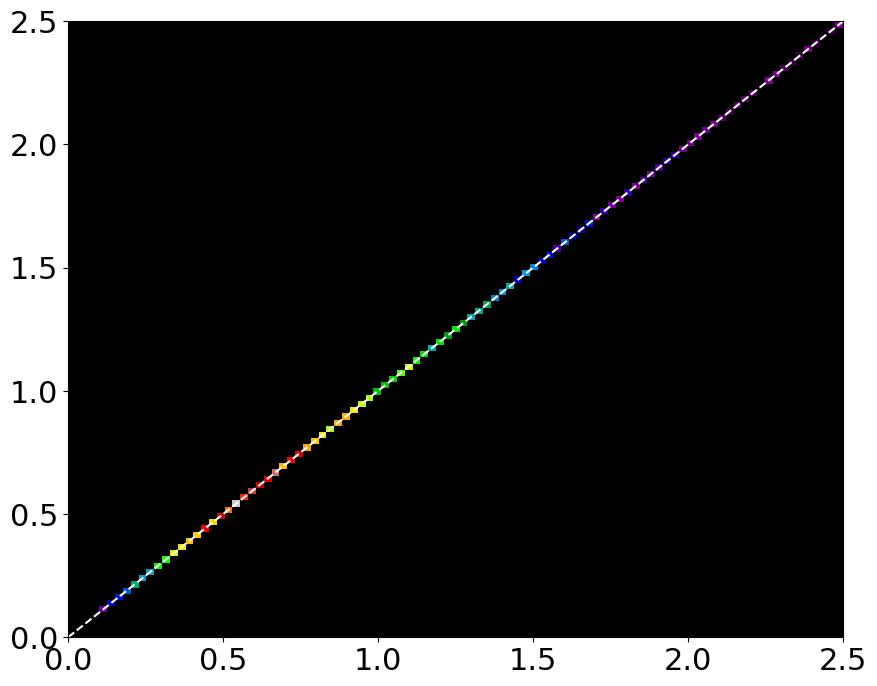

In [144]:
import matplotlib.colors as mcolors
import matplotlib

cmap = matplotlib.colormaps.get_cmap('nipy_spectral')

plt.rcParams.update({'font.size': 22})
fig, ax = plt.subplots(1, 1, figsize=(10,8))
# ax.hist2d(np.log10(c_ss),np.log10(c_bs), bins=np.linspace(0,5,100), density=True)
ax.hist2d(c_ss,c_b2,bins=[np.linspace(0,40,80),np.linspace(0,40,80)],density=True, cmap=cmap)
# ax.set_xlim([0,3])
# ax.set_xlim([0,3])
# ax.plot([1e0,1e6],[1e0,1e6],'--',color='w')
ax.set_xlabel('Single-Level Conditioning')
ax.set_ylabel('Bilevel Conditioning')
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10,8))
ax.hist2d(np.log10(c_ss),np.log10(c_b2), bins=np.linspace(0,2.5,100), density=True, cmap=cmap)
# ax.set_xlim([0,3])
# ax.set_xlim([0,3])
ax.plot([0,1e6],[0,1e6],'--',color='w')
plt.show()